# Semana 6 — Ordenación de datos y series temporales aplicado a Penonomé

Aplica las unidades 37 a 40 del curso: [ordenación de datos](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), [series temporales](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb), [análisis de datos financieros](../../../../01-python/semana-06/clase-2-mini-proyectos/u39-analisis-datos-financieros.ipynb) y el [miniproyecto de la pandemia](../../../../01-python/semana-06/clase-2-mini-proyectos/u40-pandemia-coronavirus.ipynb). Es también el notebook de cierre del proyecto.

[Proyecto](../../README.md) | [Anterior](s05-dinamica-backtracking-modulos-pandas.ipynb) | [Siguiente](../../README.md)

In [1]:
def verificar(descripcion, obtenido, esperado):
    """Compara el resultado de un ejercicio con el esperado e informa sin detener el notebook."""
    if obtenido == esperado:
        print(f"Correcto: {descripcion}")
    else:
        print(f"Incorrecto: {descripcion}. Se esperaba {esperado!r} y se obtuvo {obtenido!r}")

## Qué hace este notebook

| Sección | Unidad | Datos |
|---|---|---|
| 1. Datos ordenados: `pivot` y `melt` | u37 | base larga (tabla 99) y EML (tabla 03) |
| 2. Ordenar y agrupar | u37 | Censo 2023 (tabla 01) y base larga |
| 3. Series temporales mensuales | u38 | visitantes y divisas (ATP, tabla 11) |
| 4. Cambio porcentual y volatilidad | u38, u39 | PIB de Coclé por actividad (tabla 10) |
| 5. Series irregulares y trimestres móviles | u38 | réplicas del sismo y desempleo en Colombia (`datos/comparacion-colombia/20`) |
| 6. Análisis final con gráficos | u39, u40 | todo lo anterior |

Las funciones de carga y de ayuda están en `penonome.analisis` (ver la sección 1 del [notebook de la semana 5](s05-dinamica-backtracking-modulos-pandas.ipynb)).

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

import penonome.analisis as an
from penonome.analisis import leer

print("pandas", pd.__version__)

pandas 3.1.1


## 1. Datos ordenados: la base larga, `pivot` y `melt`

Según la [Unidad 37](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), una tabla está **ordenada** (*tidy data*) cuando cada variable es una columna, cada observación es una fila y cada valor ocupa una celda. La tabla `99_base_larga_todo.csv` del paquete sigue ese formato: una fila por dato, con su indicador, su fecha, su unidad y su fuente.

Primero se revisan los datos que faltan con `isnull().sum()`, como en la u37.

In [3]:
larga_original = leer("99_base_larga_todo.csv")
print(larga_original.shape)
print(larga_original.isnull().sum()[lambda s: s > 0])

(1074, 12)
distrito         614
corregimiento    638
nota             883
dtype: int64


Los huecos de `distrito` y `corregimiento` no son datos perdidos: significan que el dato es del nivel superior (provincia o país). La columna `nota` es opcional. Por eso no se usa `dropna()`, que borraría 645 filas válidas, sino `fillna("")`, que hace `an.base_larga()`. Así esas columnas pueden formar parte de un índice.

Con `pivot` la tabla pasa a formato **ancho** (una fila por indicador, una columna por fecha), cómodo para leer; con `melt` vuelve al formato largo. Si ninguna fila se pierde ni se duplica, la ida y vuelta devuelve exactamente la tabla original.

In [4]:
larga = an.base_larga()
claves = ["provincia", "distrito", "corregimiento", "indicador", "fecha"]
print("Filas repetidas por clave:", larga.duplicated(claves).sum())

ancha = an.a_ancho(larga)                         # pivot: fecha pasa a columnas
print("Formato ancho:", ancha.shape, "->", ancha.notna().sum().sum(), "celdas con dato")
pib_ancho = ancha[ancha.index.get_level_values("indicador").str.startswith("pib_volumen | PIB ")]
print(pib_ancho.droplevel(["distrito", "corregimiento", "unidad"]).dropna(axis=1))

de_vuelta = an.a_largo(ancha)                     # melt: las columnas vuelven a ser filas
verificar("ninguna clave repetida (pivot es posible)", int(larga.duplicated(claves).sum()), 0)
verificar("melt devuelve las 1,074 filas", len(de_vuelta), 1074)
verificar("ida y vuelta pivot -> melt idéntica a la original", an.ordenar_larga(de_vuelta).equals(an.ordenar_larga(larga)), True)

Filas repetidas por clave: 0
Formato ancho: (690, 39) -> 1074 celdas con dato
fecha                                     2018     2019     2020     2021  \
provincia indicador                                                         
Coclé     pib_volumen | PIB COCLÉ       2195.3   2121.8   1692.6   2113.2   
República pib_volumen | PIB REPÚBLICA  67316.5  69405.3  57036.5  66428.7   

fecha                                     2022     2023     2024  
provincia indicador                                               
Coclé     pib_volumen | PIB COCLÉ       2227.3   2267.5   2413.7  
República pib_volumen | PIB REPÚBLICA  73761.5  79047.5  81219.6  
Correcto: ninguna clave repetida (pivot es posible)
Correcto: melt devuelve las 1,074 filas
Correcto: ida y vuelta pivot -> melt idéntica a la original


**Error común:** usar `pivot` cuando hay claves repetidas: lanza `ValueError: Index contains duplicate entries`. En ese caso se usa `pivot_table`, que agrega los repetidos (por defecto, con la media). Por eso la celda anterior comprueba primero que no haya duplicados.

El caso contrario aparece en la tabla 03 de la EML: viene **desordenada**, con valores de dos variables (periodo y sexo) metidos en los nombres de las columnas (`oct2024_total`, `sep2025_mujeres`...). `melt` la ordena y `str.split` separa el nombre en sus dos variables.

In [5]:
eml = an.eml_tidy()
print(eml.shape)
print(eml.head(4))

tasas = (eml[eml["indicador"] == "Tasa de desempleo (%)"]
         .pivot_table(index=["area", "sexo"], columns="periodo", values="valor"))
tasas.columns = tasas.columns.strftime("%b-%Y")
print()
print(tasas)

dato = eml.query("area == 'Coclé' and sexo == 'total' and indicador == 'Tasa de desempleo (%)'")
dato = dato.set_index("periodo")["valor"]
verificar("filas de la EML ordenada (40 filas x 6 columnas de valores)", len(eml), 240)
verificar("desempleo de Coclé, sep-2025, desde la tabla ordenada", dato["2025-09-01"], 7.1)

(240, 5)
        area                  indicador      valor    periodo   sexo
0  República              Población 15+  3391445.0 2024-10-01  total
1  República      Económicamente activa  2150581.0 2024-10-01  total
2  República  Tasa de participación (%)       63.4 2024-10-01  total
3  República                    Ocupada  1941201.0 2024-10-01  total

periodo               Oct-2024  Sep-2025
area         sexo                       
Coclé        hombres       2.8       4.1
             mujeres       9.5      11.1
             total         5.7       7.1
Coclé rural  hombres       2.4       3.3
             mujeres       9.4       9.4
             total         5.2       5.8
Coclé urbana hombres       3.5       5.5
             mujeres       9.7      13.4
             total         6.3       9.1
República    hombres       7.7       8.1
             mujeres      12.4      13.2
             total         9.7      10.4
Correcto: filas de la EML ordenada (40 filas x 6 columnas de valores)
C

La tabla ordenada deja ver lo que la ancha escondía: entre octubre de 2024 y septiembre de 2025 el desempleo de Coclé subió de 5.7 % a 7.1 %, y el de las mujeres de la Coclé urbana llegó a 13.4 %. El último dato previo al sismo, agosto de 2026, bajó a 5.5 % (está en `datos/comparacion-colombia/23`, no en la tabla 03).

**Clave:** `melt` pasa de ancho a largo (columnas a filas) y `pivot` de largo a ancho. Una tabla ordenada se filtra, agrupa y grafica sin tener que reescribir nombres de columnas.

**Referencia:** [Unidad 37 — Ordenación de datos](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), secciones 2 a 8: definición de datos ordenados, `isnull`, `dropna` y `fillna`.

## 2. Ordenar y agrupar: `sort_values` y `groupby`

`groupby` divide una tabla en grupos, aplica una función a cada uno y junta los resultados ([Unidad 37](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb) y proyecto de la [Unidad 38](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb)). El caso más útil del proyecto es el que pide el `LEEME` del paquete: los seis corregimientos creados por la Ley 296 de 2022 salieron de cinco corregimientos originales, así que para comparar 2010 con 2023 hay que agruparlos a los once como un solo bloque.

In [6]:
from penonome.carga import PADRES_LEY_296      # el diccionario padre -> hijos de la semana 1

tabla01 = an.poblacion_corregimientos()
del_bloque = set(PADRES_LEY_296) | {hijo for hijos in PADRES_LEY_296.values() for hijo in hijos}
grupo = tabla01.index.map(lambda clave: "Bloque Ley 296 (11 corregimientos)" if clave in del_bloque
                          else tabla01.loc[clave, "corregimiento"])

comparable = tabla01.groupby(grupo)[["pob_2000", "pob_2010", "pob_2023"]].sum()
comparable["crecimiento_2010_2023"] = ((comparable["pob_2023"] / comparable["pob_2010"] - 1) * 100).round(1)
comparable = comparable.sort_values("crecimiento_2010_2023", ascending=False)
comparable.index.name = "grupo"
print(comparable)

verificar("corregimientos que forman el bloque", len(del_bloque), 11)
verificar("población 2023 del bloque", int(comparable.loc["Bloque Ley 296 (11 corregimientos)", "pob_2023"]), 48786)
verificar("el agrupamiento conserva el total del distrito", int(comparable["pob_2023"].sum()), 104326)

                                    pob_2000  pob_2010  pob_2023  \
grupo                                                              
El Coco                               4592.0    5605.0     11064   
Coclé                                 3637.0    4100.0      5811   
Cañaveral                             6367.0    7517.0      9324   
Penonomé (cabecera)                  15841.0   21748.0     25836   
Río Grande                            2915.0    3117.0      3505   
Bloque Ley 296 (11 corregimientos)   39096.0   43650.0     48786   

                                    crecimiento_2010_2023  
grupo                                                      
El Coco                                              97.4  
Coclé                                                41.7  
Cañaveral                                            24.0  
Penonomé (cabecera)                                  18.8  
Río Grande                                           12.4  
Bloque Ley 296 (11 corregimientos) 

Agrupado, el bloque de los once corregimientos creció 11.8 % entre 2010 y 2023: ni se despobló (como sugerían Pajonal o Tulú por separado) ni creció como El Coco, que casi duplicó su población (+97.4 %). La cabecera creció 18.8 %.

`groupby` también resume la base larga: cuántos datos hay por nivel geográfico y por unidad de medida.

In [7]:
por_provincia = larga.groupby("provincia").size().sort_values(ascending=False)
print(por_provincia.head(3))
print()
larga["tema"] = larga["indicador"].str.split(" | ", regex=False).str[0]
por_tema = larga.groupby("tema").agg(datos=("valor", "size"), fechas=("fecha", "nunique"))
print(por_tema.sort_values("datos", ascending=False).head(6))

verificar("datos de Coclé en la base larga", int(por_provincia["Coclé"]), 939)
verificar("el tema con más datos es el PIB por actividad", por_tema["datos"].idxmax(), "pib_volumen")

provincia
Coclé        939
República    135
dtype: int64

                              datos  fechas
tema                                       
pib_volumen                     140       7
ocupados_rama                    50       2
categoria                        38       2
poblacion                        36       3
visitantes                       24      24
eml_No económicamente activa     24       2
Correcto: datos de Coclé en la base larga
Correcto: el tema con más datos es el PIB por actividad


**Error común:** en pandas 3, `groupby(...).sum()` sobre una tabla con columnas de texto intenta sumarlas y falla. Se seleccionan antes las columnas numéricas (como arriba) o se usa `numeric_only=True`, la misma adaptación que hizo la u38 con el ejemplo del PDF.

**Referencia:** [Unidad 37](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb) (`sort_values`, estadísticas por columna) y [Unidad 38 — proyecto de la unidad](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb) (`groupby` y suma por grupo).

## 3. Series temporales mensuales: visitantes y divisas

La tabla 11 de la ATP trae los visitantes internacionales y las divisas de Panamá mes a mes, con un año por columna. `an.visitantes_mensuales()` la convierte en una serie temporal con `DatetimeIndex` (con `pd.to_datetime` y `set_index`, como el ejemplo del petróleo WTI de la [Unidad 38](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb)). Con ese índice se puede trocear por fecha, remuestrear y calcular estadísticas móviles.

Es un dato nacional: la ATP no publica visitantes por provincia. Sirve como contexto del turismo, que en Coclé pesa en hoteles y restaurantes.

In [8]:
mensual = an.visitantes_mensuales()
print(type(mensual.index).__name__, mensual.index.min().date(), "a", mensual.index.max().date())
print(mensual.head(3))
print()
anual = mensual.resample("YE").sum()                 # remuestreo anual: 'YE' en pandas 3
print(anual)

verificar("visitantes de 2025 (suma de los 12 meses)", int(mensual.loc["2025", "visitantes"].sum()), 3004266)
verificar("troceado por fecha: meses de 2025", len(mensual.loc["2025-01":"2025-12"]), 12)

DatetimeIndex 2024-01-01 a 2025-12-01
            visitantes  divisas_millones
fecha                                   
2024-01-01      313868             510.9
2024-02-01      260161             512.3
2024-03-01      283206             578.4

            visitantes  divisas_millones
fecha                                   
2024-12-31     2775405            5999.9
2025-12-31     3004266            6583.0
Correcto: visitantes de 2025 (suma de los 12 meses)
Correcto: troceado por fecha: meses de 2025


In [9]:
trimestral = mensual["visitantes"].resample("QE").sum()          # 'QE' = fin de trimestre
media_movil = mensual["visitantes"].rolling(window=3).mean()      # media móvil de 3 meses
interanual = an.variacion_pct(mensual["visitantes"], periodos=12) # mismo mes del año anterior

resumen = pd.DataFrame({"visitantes": mensual["visitantes"], "media_movil_3m": media_movil.round(0),
                        "var_interanual_pct": interanual.round(1)})
print(resumen.loc["2025"])
print()
print(trimestral.loc["2025"])

verificar("shift(12) y pct_change(12) dan lo mismo",
          interanual.dropna().round(6).tolist(), (mensual["visitantes"].pct_change(12) * 100).dropna().round(6).tolist())
verificar("visitantes del cuarto trimestre de 2025", int(trimestral["2025-12-31"]), 858178)
verificar("variación interanual de diciembre de 2025 (%)", round(interanual["2025-12-01"], 1), 14.0)
verificar("meses de 2025 por encima de 2024", int((interanual.dropna() > 0).sum()), 10)

            visitantes  media_movil_3m  var_interanual_pct
fecha                                                     
2025-01-01      324191        289869.0                 3.3
2025-02-01      254839        294631.0                -2.0
2025-03-01      273472        284167.0                -3.4
2025-04-01      252048        260120.0                20.4
2025-05-01      194540        240020.0                 6.2
2025-06-01      196796        214461.0                 1.6
2025-07-01      232119        207818.0                 8.2
2025-08-01      223169        217361.0                11.5
2025-09-01      194914        216734.0                11.7
2025-10-01      240393        219492.0                21.8
2025-11-01      270221        235176.0                12.3
2025-12-01      347564        286059.0                14.0

fecha
2025-03-31    852502
2025-06-30    643384
2025-09-30    650202
2025-12-31    858178
Freq: QE-DEC, Name: visitantes, dtype: int64
Correcto: shift(12) y pct_change(12) d

2025 tuvo 3,004,266 visitantes, 8.2 % más que 2024, con diez de doce meses por encima del año anterior (solo febrero y marzo bajaron). La mejora se concentró en la segunda mitad: de julio a diciembre todos los meses crecieron más de 8 %. Las divisas se mueven con los visitantes (correlación de 0.73, sección 4).

**Error común:** usar los alias de frecuencia del PDF (`'M'`, `'Q'`, `'A'`). En pandas 3 fallan con `ValueError: Invalid frequency`; hay que escribir `'ME'`, `'QE'` y `'YE'` para fin de mes, trimestre y año, y `'MS'` para inicio de mes.

**Referencia:** [Unidad 38 — Datos de series temporales](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb), secciones 7 a 10: `pd.to_datetime`, troceado con `DatetimeIndex`, `resample` y `rolling`.

## 4. Cambio porcentual, índice base 100 y volatilidad: el PIB de Coclé

La [Unidad 39](../../../../01-python/semana-06/clase-2-mini-proyectos/u39-analisis-datos-financieros.ipynb) analiza precios con tres herramientas: el cambio porcentual con `shift()` (o `pct_change()`), el rendimiento acumulado y la volatilidad como desviación estándar de los cambios. Se aplican igual al PIB anual de Coclé por actividad, 2018-2024 (INEC; 2023 preliminar y 2024 estimado).

In [10]:
pib = an.pib_anual()
print(pib.index[[0, -1]].strftime("%Y-%m-%d").tolist(), "|", pib.shape[1], "columnas")

variacion = an.variacion_pct(pib[["PIB COCLÉ", "PIB REPÚBLICA"]]).round(2)
indice = an.indice_base_100(pib[["PIB COCLÉ", "PIB REPÚBLICA"]]).round(1)
print(pd.concat({"variación %": variacion, "índice 2018 = 100": indice}, axis=1))

verificar("caída del PIB de Coclé en 2020 (%)", variacion.loc["2020", "PIB COCLÉ"].iloc[0], -20.23)
verificar("índice de Coclé en 2024 (2018 = 100)", indice.loc["2024", "PIB COCLÉ"].iloc[0], 109.9)
verificar("índice de la República en 2024 (2018 = 100)", indice.loc["2024", "PIB REPÚBLICA"].iloc[0], 120.7)

['2018-12-31', '2024-12-31'] | 20 columnas
           variación %               índice 2018 = 100              
             PIB COCLÉ PIB REPÚBLICA         PIB COCLÉ PIB REPÚBLICA
anio                                                                
2018-12-31         NaN           NaN             100.0         100.0
2019-12-31       -3.35          3.10              96.7         103.1
2020-12-31      -20.23        -17.82              77.1          84.7
2021-12-31       24.85         16.47              96.3          98.7
2022-12-31        5.40         11.04             101.5         109.6
2023-12-31        1.80          7.17             103.3         117.4
2024-12-31        6.45          2.75             109.9         120.7
Correcto: caída del PIB de Coclé en 2020 (%)
Correcto: índice de Coclé en 2024 (2018 = 100)
Correcto: índice de la República en 2024 (2018 = 100)


In [11]:
agregados = ["VALOR AGREGADO BRUTO", "Impuestos netos a los productos", "PIB COCLÉ", "PIB REPÚBLICA"]
actividades = pib.drop(columns=agregados)

cambios = an.variacion_pct(actividades)
volatilidad = cambios.std().round(1).sort_values()               # como la volatilidad de la u39
peso_2024 = (actividades.loc["2024"].iloc[0] / pib.loc["2024", "VALOR AGREGADO BRUTO"].iloc[0] * 100).round(1)
riesgo = pd.DataFrame({"volatilidad_pp": volatilidad, "peso_2024_pct": peso_2024}).sort_values("peso_2024_pct", ascending=False)
print(riesgo.head(6))

correlacion = mensual["visitantes"].corr(mensual["divisas_millones"])
print()
print(f"Correlación mensual visitantes-divisas: {correlacion:.3f}")

verificar("actividad más volátil entre las de peso mayor al 10 %", riesgo[riesgo["peso_2024_pct"] > 10]["volatilidad_pp"].idxmax(), "Construcción")
verificar("correlación visitantes-divisas", round(correlacion, 2), 0.73)

                                               volatilidad_pp  peso_2024_pct
Construcción                                             46.3           20.3
Otra producción no de mercado (gobierno)                  6.0           16.5
Industrias manufactureras                                14.7           13.1
Agricultura ganadería y pesca                             9.4           11.9
Inmobiliarias profesionales y administrativas             8.9            8.3
Comercio (incl. zonas francas)                           42.5            5.9

Correlación mensual visitantes-divisas: 0.732
Correcto: actividad más volátil entre las de peso mayor al 10 %
Correcto: correlación visitantes-divisas


La construcción es la mayor actividad de Coclé (20.3 % del valor agregado de 2024) y también la más volátil entre las grandes: en 2020 cayó 45.8 % y en 2021 casi se duplicó (+93.5 %). Es la actividad que más depende de la obra pública y la que más empleo puede perder o ganar tras un sismo, por la reconstrucción.

**Clave:** el cambio porcentual es `serie / serie.shift(1) - 1`; el índice base 100 divide todo entre el primer valor; la volatilidad es la desviación estándar de los cambios. Son las mismas fórmulas para precios diarios que para el PIB anual.

**Referencia:** [Unidad 39 — Análisis de datos financieros](../../../../01-python/semana-06/clase-2-mini-proyectos/u39-analisis-datos-financieros.ipynb), pasos 6, 7 y 9.

## 5. Series irregulares y trimestres móviles

### Réplicas del sismo

Las réplicas acumuladas localizadas por el IGC-UP no tienen frecuencia fija: son los cortes que publicó la prensa. Son datos de prensa, no una tabla oficial (los mismos puntos de `datos/analisis/replicas_acumuladas.csv`). Para comparar ritmos hay que dividir el aumento entre los **días** transcurridos, y `resample("W")` los lleva a una frecuencia semanal, con `ffill()` para las semanas sin corte ([Unidad 37](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), sustitución por el vecino más próximo).

In [12]:
replicas = an.replicas()
dias = replicas.index.to_series().diff().dt.days
ritmo = (replicas.diff() / dias).round(1)
print(pd.DataFrame({"acumuladas": replicas, "dias": dias, "replicas_por_dia": ritmo}))
print()
print(replicas.resample("W").last().ffill().astype(int))

verificar("réplicas acumuladas al 17-nov-2026", int(replicas.iloc[-1]), 1656)
verificar("días entre el primer y el último corte", (replicas.index[-1] - replicas.index[0]).days, 38)
verificar("ritmo entre el 10 y el 16 de octubre (réplicas por día)", ritmo["2026-10-16"], 101.8)

            acumuladas  dias  replicas_por_dia
2026-10-10         135   NaN               NaN
2026-10-16         746   6.0             101.8
2026-11-02        1271  17.0              30.9
2026-11-06        1452   4.0              45.2
2026-11-09        1483   3.0              10.3
2026-11-17        1656   8.0              21.6

2026-10-11     135
2026-10-18     746
2026-10-25     746
2026-11-01     746
2026-11-08    1452
2026-11-15    1483
2026-11-22    1656
Freq: W-SUN, Name: replicas_acumuladas, dtype: int64
Correcto: réplicas acumuladas al 17-nov-2026
Correcto: días entre el primer y el último corte
Correcto: ritmo entre el 10 y el 16 de octubre (réplicas por día)


El ritmo cae de unas 102 réplicas por día en la primera semana a unas 22 en la segunda mitad de noviembre: el patrón esperable de una secuencia de réplicas que se va apagando.

### Colombia: desempleo por trimestres móviles

El DANE publica el desempleo de cada ciudad en **trimestres móviles** (abr-jun, may-jul, jun-ago, jul-sep): cada dato es el promedio de tres meses y se desplaza un mes cada vez, como un `rolling(3)`. Se agrupan las ciudades afectadas por el sismo del 10 de agosto y las de control, y la diferencia entre ambas (`brecha`) es la base del método de diferencias en diferencias del notebook de comparación. Cada trimestre se fecha con el `Period` de su último mes.

In [13]:
brecha = an.brecha_colombia()
brecha.index = pd.PeriodIndex(["2026-06", "2026-07", "2026-08", "2026-09"], freq="M", name="mes_final")
print(brecha.round(2))

publicada = leer("31_colombia_diferencias_en_diferencias.csv", an.COMPARACION).set_index("trimestre_movil")
efecto = brecha["brecha"].iloc[-1] - brecha["brecha"].iloc[0]
print(f"Efecto (brecha jul-sep menos brecha abr-jun): {efecto:.2f} pp")

verificar("groupby reproduce datos/comparacion-colombia/31", brecha.round(2).values.tolist(), publicada.values.tolist())
verificar("el primer trimestre posterior al sismo termina en septiembre", str(brecha.index[-1]), "2026-09")

           afectada  control  brecha
mes_final                           
2026-06       -1.58     0.29   -1.87
2026-07       -0.80     0.00   -0.80
2026-08        0.08     0.50   -0.42
2026-09        0.80     0.62    0.18
Efecto (brecha jul-sep menos brecha abr-jun): 2.05 pp
Correcto: groupby reproduce datos/comparacion-colombia/31
Correcto: el primer trimestre posterior al sismo termina en septiembre


**Error común:** comparar un trimestre móvil con el siguiente como si fueran periodos independientes. Comparten dos de sus tres meses; por eso el estudio compara cada trimestre de 2026 con el mismo de 2025 (`cambio_pp`) y no trimestres consecutivos entre sí.

**Referencia:** [Unidad 38](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb), secciones 5, 6 y 8 (`Timedelta`, `Period`, `DatetimeIndex`) y estadística móvil; [Unidad 37](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), `ffill`.

## 6. Análisis final: la economía de Coclé antes y después del sismo

Como en los miniproyectos de la [Unidad 39](../../../../01-python/semana-06/clase-2-mini-proyectos/u39-analisis-datos-financieros.ipynb) y la [Unidad 40](../../../../01-python/semana-06/clase-2-mini-proyectos/u40-pandemia-coronavirus.ipynb), el análisis sigue pasos: una pregunta, datos preparados, gráficos y una lectura de cada uno.

La pregunta del análisis es: ¿en qué situación llegó la economía de Coclé al sismo del 9 de octubre de 2026 y qué cabe esperar del desempleo?

Los cuatro gráficos usan la misma paleta (azul, naranja y agua), un título que dice qué se ve, nombres de ejes y la fuente al pie.

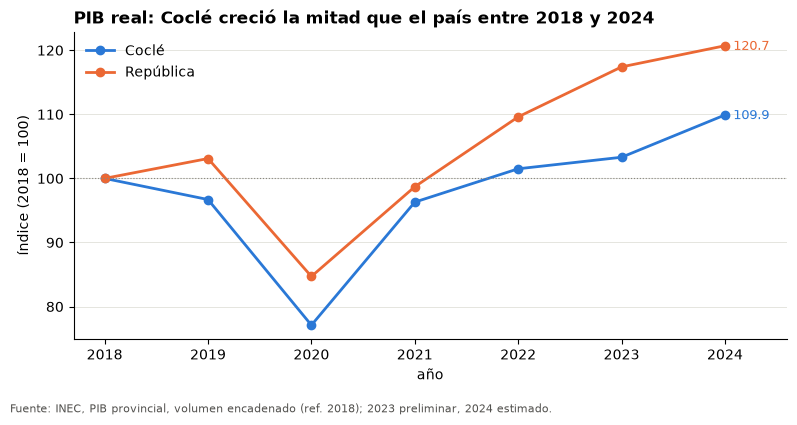

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(indice.index.year, indice["PIB COCLÉ"], color=an.AZUL, linewidth=2, marker="o", label="Coclé")
ax.plot(indice.index.year, indice["PIB REPÚBLICA"], color=an.NARANJA, linewidth=2, marker="o", label="República")
ax.axhline(100, color="#898781", linewidth=0.8, linestyle=":")
for serie, color in (("PIB COCLÉ", an.AZUL), ("PIB REPÚBLICA", an.NARANJA)):
    ax.annotate(f"{indice[serie].iloc[-1]:.1f}", (2024, indice[serie].iloc[-1]), textcoords="offset points",
                xytext=(6, -3), color=color, fontsize=9)
ax.set_xlim(2017.7, 2024.6)
ax.legend(frameon=False, loc="upper left")
an.estilo_eje(ax, "PIB real: Coclé creció la mitad que el país entre 2018 y 2024",
              "año", "índice (2018 = 100)",
              "INEC, PIB provincial, volumen encadenado (ref. 2018); 2023 preliminar, 2024 estimado.")
plt.show()

Los dos cayeron en 2020, pero Coclé recuperó su nivel de 2018 recién en 2022 y en 2024 estaba apenas 9.9 % por encima, frente a 20.7 % del país. El sismo llegó a una economía que crecía, aunque más despacio que el promedio nacional.

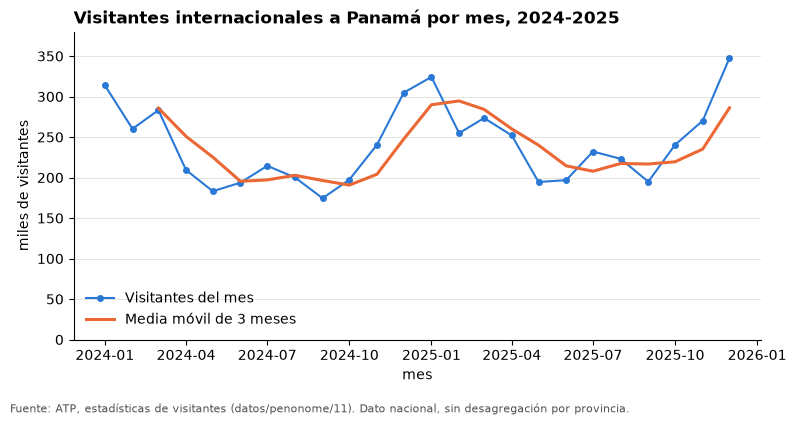

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(mensual.index, mensual["visitantes"] / 1000, color=an.AZUL, linewidth=1.5, marker="o", markersize=4,
        label="Visitantes del mes")
ax.plot(media_movil.index, media_movil / 1000, color=an.NARANJA, linewidth=2.2, label="Media móvil de 3 meses")
ax.set_ylim(0, 380)
ax.legend(frameon=False, loc="lower left")
an.estilo_eje(ax, "Visitantes internacionales a Panamá por mes, 2024-2025", "mes", "miles de visitantes",
              "ATP, estadísticas de visitantes (datos/penonome/11). Dato nacional, sin desagregación por provincia.")
plt.show()

La serie tiene una estacionalidad clara (picos en diciembre-enero, mínimos en mayo y septiembre) y la media móvil muestra que 2025 terminó en un nivel más alto que 2024. Para Coclé, cuyo turismo es de playa y montaña, el sismo cayó en octubre, justo antes de la temporada alta.

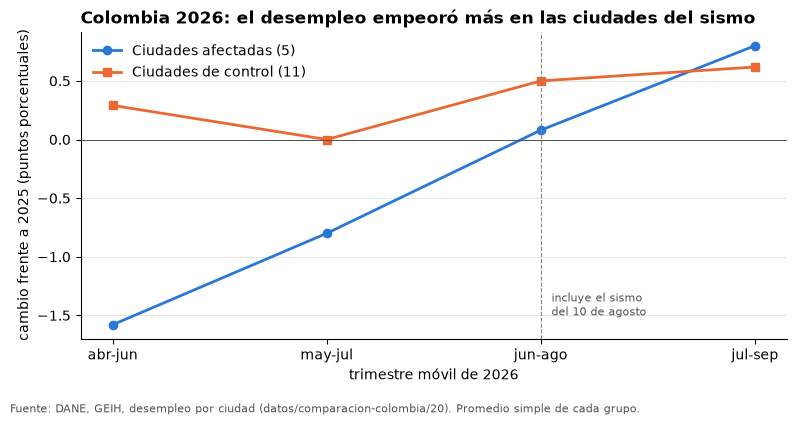

In [16]:
etiquetas = ["abr-jun", "may-jul", "jun-ago", "jul-sep"]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(etiquetas, brecha["afectada"], color=an.AZUL, linewidth=2, marker="o", label="Ciudades afectadas (5)")
ax.plot(etiquetas, brecha["control"], color=an.NARANJA, linewidth=2, marker="s", label="Ciudades de control (11)")
ax.axhline(0, color="#52514e", linewidth=0.7)
ax.axvline(2, color="#898781", linewidth=0.8, linestyle="--")
ax.text(2.05, -1.5, "incluye el sismo\ndel 10 de agosto", fontsize=8, color="#52514e")
ax.legend(frameon=False, loc="upper left")
an.estilo_eje(ax, "Colombia 2026: el desempleo empeoró más en las ciudades del sismo",
              "trimestre móvil de 2026", "cambio frente a 2025 (puntos porcentuales)",
              "DANE, GEIH, desempleo por ciudad (datos/comparacion-colombia/20). Promedio simple de cada grupo.")
plt.show()

Antes del sismo las ciudades afectadas mejoraban más rápido que las de control (brecha de -1.87 puntos); en jul-sep la ventaja desapareció (+0.18). La diferencia, 2.05 puntos, es la estimación del efecto del sismo. El DANE no marca ese cambio como estadísticamente significativo y solo hay dos meses posteriores: es una señal, no una prueba.

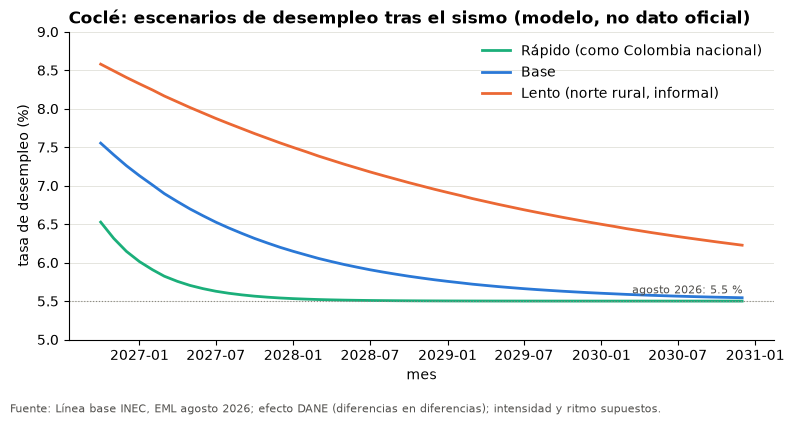

Correcto: los tres escenarios vuelven cerca de la línea base en 2030 (menos de 1 pp)


In [17]:
escenarios = {"Rápido (como Colombia nacional)": (0.5, 3), "Base": (1.0, 9), "Lento (norte rural, informal)": (1.5, 24)}
meses = pd.date_range("2026-10-01", "2030-12-01", freq="MS")
proyeccion = pd.DataFrame({nombre: an.proyectar_desempleo(5.5, efecto * factor, vida, len(meses))
                           for nombre, (factor, vida) in escenarios.items()}, index=meses)

fig, ax = plt.subplots(figsize=(8, 4.2))
for (nombre, serie), color in zip(proyeccion.items(), (an.AGUA, an.AZUL, an.NARANJA)):
    ax.plot(serie.index, serie, color=color, linewidth=2, label=nombre)
ax.axhline(5.5, color="#898781", linewidth=0.8, linestyle=":")
ax.text(meses[-1], 5.6, "agosto 2026: 5.5 %", ha="right", fontsize=8, color="#52514e")
ax.set_ylim(5, 9)
ax.legend(frameon=False, loc="upper right")
an.estilo_eje(ax, "Coclé: escenarios de desempleo tras el sismo (modelo, no dato oficial)",
              "mes", "tasa de desempleo (%)",
              "Línea base INEC, EML agosto 2026; efecto DANE (diferencias en diferencias); intensidad y ritmo supuestos.")
plt.show()

verificar("los tres escenarios vuelven cerca de la línea base en 2030 (menos de 1 pp)",
          bool((proyeccion.loc["2030"].mean() - 5.5 < 1).all()), True)

En el escenario base el desempleo de Coclé sube a 7.6 % en octubre de 2026 y vuelve a menos de 6 % a mediados de 2028; en el lento, con un golpe más fuerte en el norte rural e informal, sigue por encima de 6 % en 2030. Qué escenario se cumple lo dirá la próxima EML del INEC.

## Conclusiones del proyecto

El proyecto responde a una pregunta real, el desempleo y la economía de Penonomé y Coclé antes y después del sismo del 9 de octubre de 2026, con datos oficiales verificados y con lo visto en las seis semanas del módulo de Python.

| Semana | Qué se aprendió | Dónde se aplicó |
|---|---|---|
| [1](s01-listas-diccionarios-conjuntos.ipynb) | Listas, tuplas, diccionarios, JSON y conjuntos | lectura de los CSV con el módulo `csv` (`penonome/carga.py`), CRUD del diccionario de corregimientos, conjuntos de corregimientos nuevos |
| [2](s02-funciones-clausuras-clases.ipynb) | Funciones, recursividad, clausuras y clases | tasas del mercado laboral, `filter`/`map`/`reduce` sobre el PIB, clases `Corregimiento` y `Fuente` (`penonome/modelos.py`) |
| [3](s03-pilas-colas-busqueda-hash.ipynb) | Pilas, colas, búsqueda y tablas hash | pila de correcciones del 24-nov-2026, cola de fuentes por verificar, índice hash de fuentes por URL |
| [4](s04-ordenamiento-greedy-divide-y-venceras.ipynb) | Ordenamiento, greedy y divide y vencerás | los cinco algoritmos sobre las 1,074 filas, prioridad de corregimientos con presupuesto, mejor tramo del turismo |
| [5](s05-dinamica-backtracking-modulos-pandas.ipynb) | Programación dinámica, retroceso, módulos, Series y DataFrames | mejor tramo del PIB, proyección memorizada, combinaciones de corregimientos, `penonome/analisis.py` |
| 6 | Datos ordenados, series temporales y miniproyectos | `pivot`/`melt` de la base larga, `resample` y `rolling` de visitantes, volatilidad del PIB y este análisis final |

### Hallazgos principales

1. Población: Penonomé tiene 104,326 habitantes (Censo 2023); la cabecera concentra uno de cada cuatro. Agrupado como pide la Ley 296, el bloque de los once corregimientos creció 11.8 % desde 2010 y El Coco casi se duplicó.
2. Empleo: el desempleo de Coclé fue 5.7 % (oct-2024), 7.1 % (sep-2025) y 5.5 % (ago-2026, último dato previo al sismo), siempre por debajo del país, pero con 59.5 % de informalidad no agrícola.
3. Economía: el PIB real de Coclé creció 9.9 % entre 2018 y 2024, la mitad que la República; su mejor tramo fue 2021-2024, y la construcción, su mayor actividad, es también la más volátil.
4. Sismo: las réplicas pasaron de unas 100 por día a unas 20; en Colombia, un sismo comparable sumó unos 2 puntos al desempleo de las ciudades afectadas.
5. Proyección: con ese efecto, los escenarios llevan el desempleo de Coclé a entre 6.3 % y 8.5 % de promedio en 2026, El escenario rápido vuelve a la línea base en 2029; el lento sigue por encima de 6 % al cierre de 2030. Es un modelo, no un dato.

### Límites

Ninguna tabla oficial es posterior al sismo; los visitantes y la ocupación hotelera son datos nacionales; las cifras de daños y réplicas vienen de prensa y de SINAPROC.

### Para seguir leyendo

- El documento completo del estudio, con todas las fuentes: [documento/estudio-penonome.md](../../documento/estudio-penonome.md).
- Las verificaciones contra las fuentes originales (carpeta `verificaciones/`): [paquetes de datos](../../investigacion/verificaciones/2026-11-24-paquetes-de-datos.md) y [documento](../../investigacion/verificaciones/2026-11-24-documento.md).
- La comparación con Colombia: [analisis-penonome.ipynb](../../analisis-penonome.ipynb).

[Proyecto](../../README.md) | [Anterior](s05-dinamica-backtracking-modulos-pandas.ipynb) | [Siguiente](../../README.md)